# HOHypEmb quickstart

HOHypEmb embeds a **simplicial complex** (a graph plus filled simplices: triangles, tetrahedra,
...) in the Poincaré disk. The **classical** embedding sees only the graph. **HHO** adds a second
layer with one point per filled simplex, coupled to its vertices (strength μ) and to overlapping
simplices (strength γ). A node's radius is fixed by its weighted degree and is identical in both
embeddings, so HHO only moves angles: it pulls the members of each simplex together.

## 1. Bring your own data

Give a networkx graph and the list of simplices you consider *filled*. Each simplex must be a
clique of the graph (all its edges present). Node ids can be any hashable value: they are
relabeled `0..n-1`, and the original ids are kept in `node_names`.

In [1]:
import sys

import matplotlib.pyplot as plt
import networkx as nx

sys.path.insert(0, "..")  # finds hohypemb/ in the repository; not needed if you copied or installed it
import hohypemb as hh

G = nx.Graph([("ana", "ben"), ("ana", "cleo"), ("ben", "cleo"), ("cleo", "dan"),
              ("dan", "eve"), ("cleo", "eve"), ("eve", "fay"), ("dan", "fay")])
my_complex = hh.SimplicialComplex.from_graph(G, [("ana", "ben", "cleo")], name="toy")
print(my_complex.n_nodes, "nodes,", my_complex.one_skeleton.number_of_edges(), "edges")
print("filled triangles:", my_complex.filled_triangles())
print("empty triangles: ", my_complex.empty_triangles())
print("index -> original id:", dict(enumerate(my_complex.node_names)))

toy_params = hh.presets.EMBEDDING_PARAMS["default"]
toy_hho = hh.HHOEmbedder(mu=15, gamma=0.5, **toy_params).fit(my_complex, seed=0)
print("node radii:", {name: round(float(r), 3) for name, r in zip(my_complex.node_names, toy_hho.radii())})

6 nodes, 8 edges
filled triangles: [(0, 1, 2)]
empty triangles:  [(2, 3, 4), (3, 4, 5)]
index -> original id: {0: 'ana', 1: 'ben', 2: 'cleo', 3: 'dan', 4: 'eve', 5: 'fay'}
node radii: {'ana': 0.96, 'ben': 0.96, 'cleo': 0.92, 'dan': 0.94, 'eve': 0.94, 'fay': 0.96}


The last lines embed your complex with HHO and print each node's radius, keyed by original id.
`default` is only a starting point: `beta` must match your graph's degree scale. Pick it on the order of
the typical weighted degree, so that the radii spread over (0, 1) and few nodes sit at r ≈ 0.

## 2. A synthetic example

A 500-node Holme–Kim graph in which about half of the triangles are filled. We keep its giant
component: the embedders need a connected graph.

In [2]:
from hohypemb.datasets.synthetic import planted_surfaces

sc = planted_surfaces("holme_kim", p_surface=50).giant_component()
print(sc.n_nodes, "nodes,", sc.one_skeleton.number_of_edges(), "edges,",
      len(sc.filled_triangles()), "filled and", len(sc.empty_triangles()), "empty triangles")

500 nodes, 996 edges, 87 filled and 91 empty triangles


## 3. Embed and plot

`hh.presets.EMBEDDING_PARAMS` holds tested embedding parameters such as `beta`, which sets the
radial scale and must match the degree scale of your graph (the presets in `hohypemb.presets` are
worked examples). The couplings μ and
γ are chosen separately: μ = 15 and γ = 0.5 work well for this graph, and the good range depends
on the graph (see `02_cora.ipynb`, which tunes μ and γ).
Filled triangles are shaded.

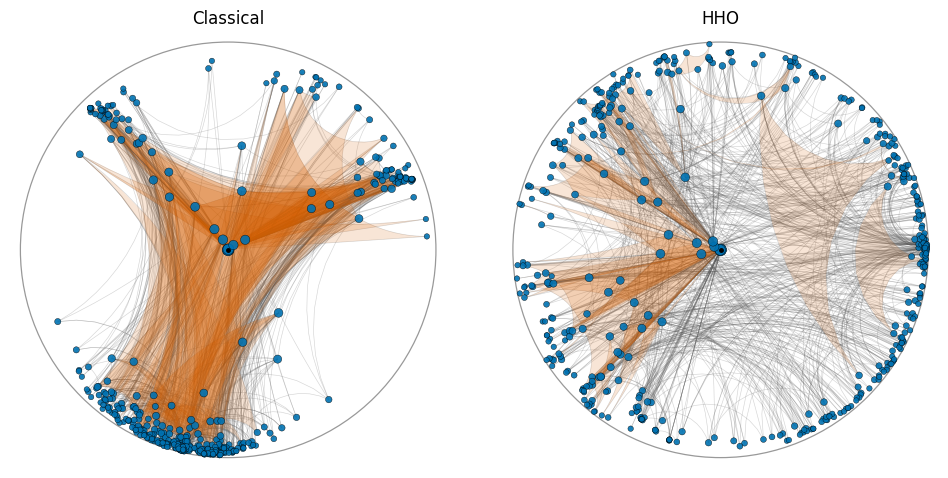

In [3]:
params = hh.presets.EMBEDDING_PARAMS["synthetic_holme_kim"]
classical = hh.ClassicalEmbedder(**params).fit(sc, seed=0)
hho = hh.HHOEmbedder(mu=15, gamma=0.5, **params).fit(sc, seed=0)
fig = hh.plotting.plot_comparison(sc, classical, hho)
plt.show()

## Where next

* `02_cora.ipynb`: nodes with labels. Predict fields (k-NN), recover co-authors, compare with graph distances, tune μ and γ.
* `03_ecoli.ipynb`: groups of nodes (protein complexes). Markers, recovering complex partners, and how much
  tighter each complex gets.
* `04_synthetic_markers.ipynb`: the classical and HHO embeddings and the area markers on two random-graph models.